# Núcleo 5 — Las 24 jurisdicciones comparadas

Los Núcleos 1 a 4 miran a Córdoba. Acá pongo a las 23 provincias y a CABA en el mismo
plano, con la misma serie del Núcleo 1, para responder tres preguntas:

1. ¿A alguna jurisdicción le fue mejor o peor que al resto entre 2003 y 2025?
2. ¿Cómo cambió la porción de cada una en lo que se reparte, y por qué?
3. ¿Cada una recibe hoy lo que le marca su coeficiente legal?

La comparación es en montos totales, no por habitante: el repositorio no tiene datos de
población por provincia. Trabajo sobre `data/processed/comparativo_provincias.csv` y
`data/processed/coparticipacion_real.csv`, generados por
`scripts/build_comparativo_provincias.py` y `scripts/process_coparticipacion.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
sys.path.insert(0, str(BASE_DIR / "scripts"))
from build_comparativo_provincias import build_comparativo, participaciones_anuales  # noqa: E402

# Misma paleta que los demás notebooks: los tres primeros slots categóricos (validados
# para usarse juntos) y gris para el resto de las jurisdicciones.
COLOR_CORDOBA = "#2a78d6"       # slot 1 - azul
COLOR_BUENOS_AIRES = "#eb6834"  # slot 2 - naranja
COLOR_CABA = "#1baf7a"          # slot 3 - aqua
COLOR_RESTO = "#c9c8c1"

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

comparativo = build_comparativo().set_index("provincia")
participacion = participaciones_anuales()
real = pd.read_csv(BASE_DIR / "data" / "processed" / "coparticipacion_real.csv").pivot(
    index="anio", columns="provincia", values="monto_real_base2016"
)


def ar(valor, decimales=2):
    """Formato argentino: coma decimal, punto de miles."""
    return f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")


print(f"Jurisdicciones: {len(comparativo)}  |  Años: {participacion.index.min()}-{participacion.index.max()}")
assert len(comparativo) == 24

Jurisdicciones: 24  |  Años: 2003-2025


## 1. Crecimiento real 2003-2025, jurisdicción por jurisdicción

Cuántas veces se multiplicó la coparticipación real (pesos constantes de 2016) de cada
jurisdicción entre 2003 y 2025. La línea vertical es el total de las 24.

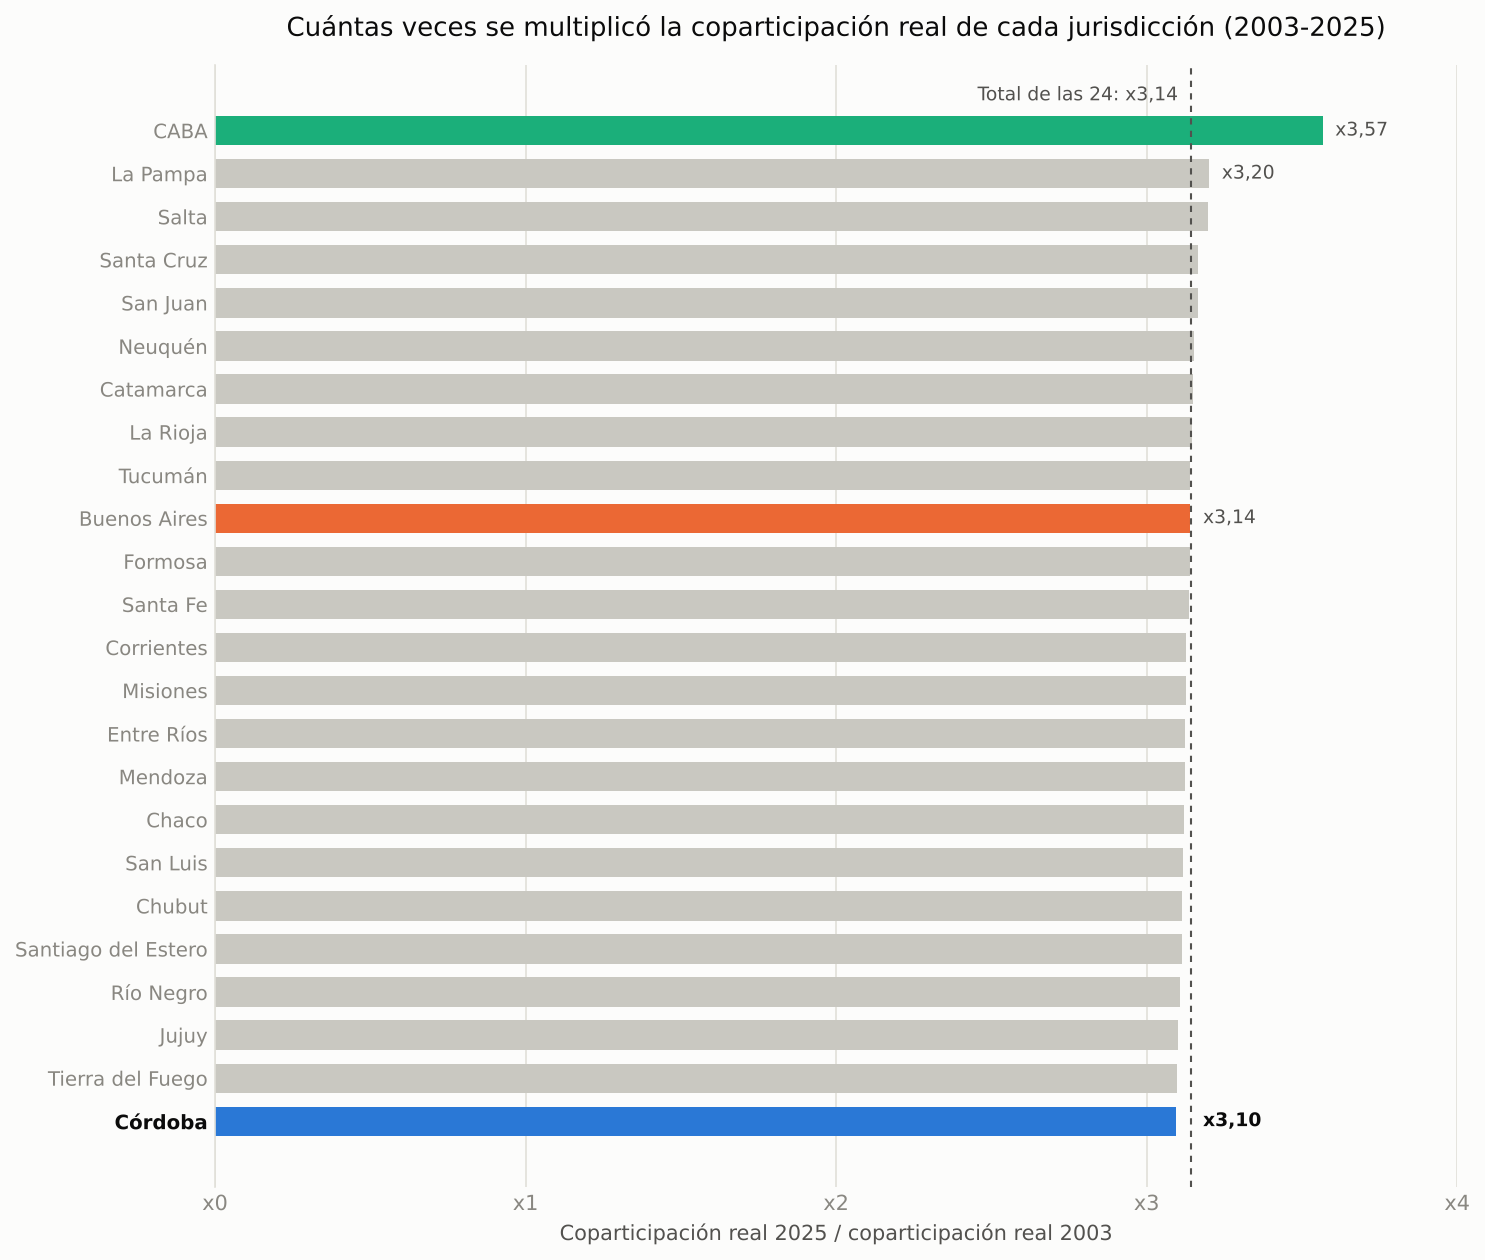

provincia
Córdoba                3.10
Tierra del Fuego       3.10
Jujuy                  3.10
Río Negro              3.11
Santiago del Estero    3.11
Chubut                 3.12
San Luis               3.12
Chaco                  3.12
Mendoza                3.12
Entre Ríos             3.12
Misiones               3.13
Corrientes             3.13
Santa Fe               3.14
Formosa                3.14
Buenos Aires           3.14
Tucumán                3.14
La Rioja               3.15
Catamarca              3.15
Neuquén                3.15
San Juan               3.17
Santa Cruz             3.17
Salta                  3.20
La Pampa               3.20
CABA                   3.57


In [2]:
orden = comparativo.sort_values("multiplicador_real_2003_2025")
total_real = real.sum(axis=1)
multiplicador_total = total_real.loc[2025] / total_real.loc[2003]

colores = [
    COLOR_CORDOBA if p == "Córdoba" else COLOR_CABA if p == "CABA" else
    COLOR_BUENOS_AIRES if p == "Buenos Aires" else COLOR_RESTO
    for p in orden.index
]

fig, ax = plt.subplots(figsize=(10, 8.5), dpi=150)
ax.barh(orden.index, orden["multiplicador_real_2003_2025"], color=colores, height=0.68)
ax.axvline(multiplicador_total, color=INK_SECONDARY, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(
    f"Total de las 24: x{ar(multiplicador_total)}", (multiplicador_total, len(orden) - 0.4),
    xytext=(-6, 0), textcoords="offset points", ha="right", va="bottom",
    fontsize=9, color=INK_SECONDARY,
)

# Etiquetas solo para las destacadas y para el máximo del resto (el mínimo es Córdoba).
# Arrancan a la derecha de la línea del total para no cruzarla.
resto = orden.drop(["Córdoba", "CABA", "Buenos Aires"])
etiquetar = {"Córdoba", "CABA", "Buenos Aires", resto.index[-1]}
for i, (provincia, fila) in enumerate(orden.iterrows()):
    if provincia in etiquetar:
        x = max(fila["multiplicador_real_2003_2025"], multiplicador_total)
        ax.annotate(
            f"x{ar(fila['multiplicador_real_2003_2025'])}", (x, i),
            xytext=(6, 0), textcoords="offset points", ha="left", va="center",
            fontsize=9, color=INK_PRIMARY if provincia == "Córdoba" else INK_SECONDARY,
            fontweight="bold" if provincia == "Córdoba" else "normal",
        )

for etiqueta in ax.get_yticklabels():
    if etiqueta.get_text() == "Córdoba":
        etiqueta.set_fontweight("bold")
        etiqueta.set_color(INK_PRIMARY)

ax.set_title(
    "Cuántas veces se multiplicó la coparticipación real de cada jurisdicción (2003-2025)",
    fontsize=12.5, color=INK_PRIMARY, pad=14,
)
ax.set_xlabel("Coparticipación real 2025 / coparticipación real 2003", fontsize=10)
ax.set_xlim(0, 4)
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"x{x:.0f}"))
ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "bottom"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
ax.tick_params(axis="y", labelsize=9.5)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "provincias_multiplicador_real_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()

print(orden["multiplicador_real_2003_2025"].round(2).to_string())

Entre 2003 y 2025 la coparticipación real de las 24 jurisdicciones se multiplicó por
3,14. Veintidós de ellas quedan entre x3,10 y x3,20: dentro del régimen, ninguna
provincia creció mucho más rápido que otra. Tiene sentido, porque el reparto sigue
coeficientes fijos desde 1988 y lo que mueve la plata de todas a la vez es la
recaudación nacional.

La única que se despega es CABA (x3,57), y no por su economía sino por cambios en su
propio régimen (sección 2). Córdoba queda última por poco (x3,10): su porción en el
reparto bajó de 8,41% en 2003 a 8,29% en 2025, por lo que se explica en la sección 3.

En todas, salvo CABA, el máximo real fue 2022, y 2025 queda entre 10% y 13% por debajo.

## 2. La porción de cada jurisdicción, año por año

Participación de cada una en lo que se repartió entre las 24, medida como diferencia en
puntos porcentuales contra su propia participación de 2003. Así entran en un mismo eje
Buenos Aires (más de 20% del reparto) y Tierra del Fuego (poco más de 1%).

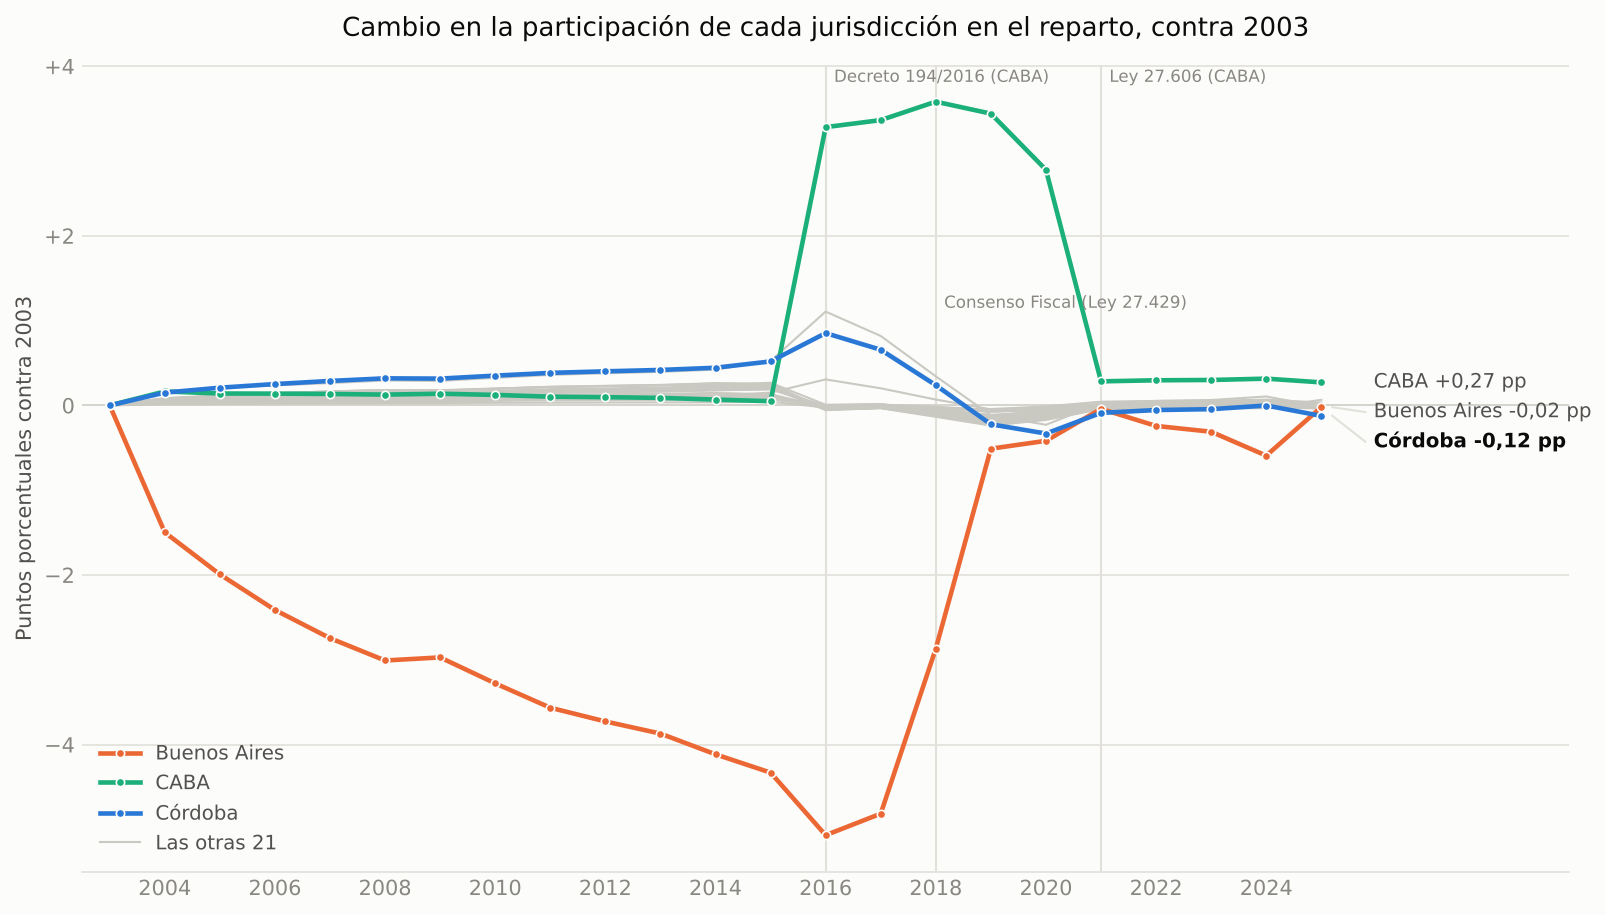

provincia,Buenos Aires,CABA,Córdoba,Santa Fe,San Luis
anio,,,,,
2003,22.72,2.00,8.41,8.53,2.12
2015,18.39,2.05,8.93,9.05,2.27
2017,17.90,5.37,9.07,9.35,2.32
2019,22.21,5.44,8.19,8.41,2.08
2021,22.68,2.29,8.32,8.56,2.11
2025,22.70,2.27,8.29,8.51,2.10


In [3]:
cambio_pp = (participacion - participacion.loc[2003]) * 100
destacadas = {"Buenos Aires": COLOR_BUENOS_AIRES, "CABA": COLOR_CABA, "Córdoba": COLOR_CORDOBA}

fig, ax = plt.subplots(figsize=(11, 6.2), dpi=150)
for provincia in cambio_pp.columns:
    if provincia not in destacadas:
        ax.plot(cambio_pp.index, cambio_pp[provincia], color=COLOR_RESTO, linewidth=1, zorder=1)
for provincia, color in destacadas.items():
    ax.plot(
        cambio_pp.index, cambio_pp[provincia], color=color, linewidth=2.2, marker="o", markersize=4,
        markerfacecolor=color, markeredgecolor=SURFACE, markeredgewidth=0.8, label=provincia, zorder=3,
    )
ax.plot([], [], color=COLOR_RESTO, linewidth=1, label="Las otras 21")

# Etiquetas directas al final: los tres valores de 2025 quedan muy cerca, así que se
# separan verticalmente (mínimo 0,35 pp) con una guía fina hasta el punto real.
finales = sorted(((cambio_pp.loc[2025, p], p) for p in destacadas), reverse=True)
y_previa = None
for valor, provincia in finales:
    y = valor if y_previa is None else min(valor, y_previa - 0.35)
    y_previa = y
    if abs(y - valor) > 0.01:
        ax.plot([2025.2, 2025.8], [valor, y], color=GRID_COLOR, linewidth=1, zorder=1)
    ax.annotate(
        f"{provincia} {valor:+.2f} pp".replace(".", ","), (2025.8, y), xytext=(4, 0),
        textcoords="offset points", ha="left", va="center", fontsize=9.5,
        color=INK_PRIMARY if provincia == "Córdoba" else INK_SECONDARY,
        fontweight="bold" if provincia == "Córdoba" else "normal",
    )

hitos = {
    2016: ("Decreto 194/2016 (CABA)", 1.0),
    2018: ("Consenso Fiscal (Ley 27.429)", 0.72),
    2021: ("Ley 27.606 (CABA)", 1.0),
}
for anio, (texto, altura) in hitos.items():
    ax.axvline(anio, color=GRID_COLOR, linewidth=1, zorder=0)
    ax.annotate(texto, (anio, altura), xycoords=("data", "axes fraction"), xytext=(4, -2),
                textcoords="offset points", ha="left", va="top", fontsize=8, color=INK_MUTED)

ax.axhline(0, color=INK_MUTED, linewidth=0.8, zorder=0)
ax.set_title("Cambio en la participación de cada jurisdicción en el reparto, contra 2003",
             fontsize=12.5, color=INK_PRIMARY, pad=14)
ax.set_ylabel("Puntos porcentuales contra 2003", fontsize=10)
ax.set_xlim(2002.5, 2029.5)
ax.set_xticks(range(2004, 2026, 2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:+.0f}".replace("-", "−") if x else "0"))
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
legend = ax.legend(frameon=False, loc="lower left", fontsize=9.5)
for text in legend.get_texts():
    text.set_color(INK_SECONDARY)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "provincias_participacion_2003_2025.png", dpi=300, facecolor=SURFACE)
plt.show()

(participacion.loc[[2003, 2015, 2017, 2019, 2021, 2025], ["Buenos Aires", "CABA", "Córdoba", "Santa Fe", "San Luis"]] * 100).round(2)

Las líneas grises casi no se mueven: para la mayoría, la porción del reparto en 2025 es
la misma que en 2003. Los movimientos grandes son tres, y los tres vienen de cambios de
reglas, no de la economía de cada provincia:

- **Buenos Aires** perdió 5 puntos entre 2003 y 2016 (de 22,7% a 17,7%) y los recuperó
  desde 2018. La serie muestra el mecanismo: hasta 2017 su asignación de Ganancias (el
  Fondo del Conurbano) fue un monto nominal fijo de $746 millones por año, mientras las
  asignaciones de Ganancias de las demás provincias crecían con la recaudación. El
  Consenso Fiscal eliminó esas asignaciones en 2018, y desde 2019 Buenos Aires vuelve a
  rondar el 22%.
- **CABA** pasó de alrededor de 2% a 5,3%-5,6% entre 2016 y 2019, cuando el Decreto
  194/2016 le subió el coeficiente para financiar el traspaso de la Policía Federal, y
  volvió a ~2,3% desde 2021 con la Ley 27.606. El 1,55% adicional que Nación le
  transfiere desde la cautelar de la Corte Suprema de diciembre de 2022 no aparece en
  esta serie de Hacienda.
- **Córdoba, Santa Fe y San Luis** suben en 2015-2016 (la línea gris de arriba es Santa
  Fe) y vuelven a bajar desde 2017. Coincide con los fallos de la Corte Suprema de
  noviembre de 2015 que les dejaron de descontar el 15% destinado a la ANSES antes que
  al resto; las demás provincias lo recuperaron de a poco entre 2016 y 2020.

Cuando una jurisdicción gana porción, las demás la pierden: el pico de CABA y la
recuperación de Buenos Aires se ven como una leve baja de todas las líneas grises.

## 3. ¿Cada jurisdicción recibe lo que marca su coeficiente legal?

Comparo la participación de 2025 contra el coeficiente de la Ley 23.548 renormalizado
entre las 24 (la misma base del Núcleo 2), con y sin la compensación del Consenso
Fiscal. Esa compensación es un monto fijado para cada provincia, no un porcentaje de lo
recaudado, así que no sigue los coeficientes.

In [4]:
tabla = comparativo[[
    "coeficiente_legal_renormalizado", "participacion_2025_sin_compensacion",
    "participacion_2025", "brecha_vs_coeficiente_pp", "peso_compensacion_2025",
]].copy()
tabla[["coeficiente_legal_renormalizado", "participacion_2025_sin_compensacion", "participacion_2025",
       "peso_compensacion_2025"]] *= 100
tabla["sin_compensacion_menos_coeficiente_pp"] = (
    tabla["participacion_2025_sin_compensacion"] - tabla["coeficiente_legal_renormalizado"]
)
tabla = tabla.sort_values("brecha_vs_coeficiente_pp", ascending=False)
print(f"Máxima diferencia sin la compensación: {tabla['sin_compensacion_menos_coeficiente_pp'].abs().max():.2f} pp "
      f"({tabla['sin_compensacion_menos_coeficiente_pp'].abs().idxmax()})")
tabla.round(2)

Máxima diferencia sin la compensación: 0.15 pp (Santa Fe)


,coeficiente_legal_renormalizado,participacion_2025_sin_compensacion,participacion_2025,brecha_vs_coeficiente_pp,peso_compensacion_2025,sin_compensacion_menos_coeficiente_pp
provincia,,,,,,
Buenos Aires,21.21,21.17,22.70,1.49,10.81,-0.04
Salta,3.70,3.69,3.82,0.12,7.52,-0.01
Misiones,3.19,3.18,3.21,0.02,5.12,-0.01
Tucumán,4.60,4.59,4.58,-0.01,4.35,-0.01
Corrientes,3.59,3.58,3.57,-0.02,4.06,-0.01
Neuquén,1.68,1.67,1.65,-0.03,3.01,-0.00
Chubut,1.53,1.52,1.49,-0.04,2.01,-0.00
Chaco,4.82,4.81,4.78,-0.04,3.72,-0.01
Jujuy,2.74,2.74,2.70,-0.05,2.91,-0.01


Sin la compensación del Consenso Fiscal, cada jurisdicción recibe en 2025 prácticamente
su coeficiente legal: la diferencia es menor a 0,05 puntos en 23 de las 24. La excepción
es Santa Fe (+0,15 puntos), y no identifiqué por qué. Eso confirma que la serie está bien
armada y que el reparto automático funciona como dice la ley.

La brecha contra el coeficiente sale casi entera de la compensación. En 2025 fueron
$2,5 billones (4,4% de lo repartido) y Buenos Aires se llevó el 56%: es el 10,8% de lo
que recibió, contra 1,2% en el caso de Córdoba. La Pampa, San Luis y CABA no reciben
compensación.

Por eso Buenos Aires queda 1,49 puntos por encima de su coeficiente y Córdoba es la que
más abajo queda (−0,29 puntos). Si esos $2,5 billones se hubieran repartido según los
coeficientes, Córdoba habría recibido unos $157.100 millones más en 2025.

## 4. Conclusiones

- Dentro del régimen, a ninguna provincia le fue mucho mejor que a otra: 22 de las 24
  multiplicaron su coparticipación real entre 3,10 y 3,20 veces entre 2003 y 2025. Lo
  que manda es la recaudación nacional, que mueve a todas juntas.
- Los cambios en el reparto vienen de reglas puntuales, no de la economía de cada
  provincia: el Fondo del Conurbano congelado hasta 2017, el coeficiente de CABA entre
  2016 y 2020 y el fallo de 2015 sobre la detracción para la ANSES.
- Hoy la única fuente relevante de diferencias es la compensación del Consenso Fiscal,
  que va en más de la mitad a Buenos Aires. Es la razón por la que Córdoba recibe 0,29
  puntos menos que su coeficiente legal.
- Limitaciones: la comparación es en montos totales, no por habitante, porque el
  repositorio no tiene datos de población por provincia. Y el 1,55% adicional de CABA por
  la cautelar de 2022 no figura en la serie de Hacienda que uso.